# Multi-FOV / sample demo

This notebook processes a small synthetic **sample** of four fields of view (FOVs): each FOV
on its own from images to molecules and cells, then the sample as a whole, placed, exported
and reported. It uses the `sample-tiny-v1` preset
([Synthetic sample scene](../../docs/synthetic-sample-scene.md)): a 2 × 2 grid of FOVs of
5 × 36 × 36 voxels cut from one scene, 4 rounds × 4 channels, seed 42. The methods are
classical (no learned model), nothing is downloaded, and it runs in well under a minute on
one CPU. It needs the `multiview-stitcher` and `anndata` extras
([Installation](../../docs/get-started/installation.md)). Everything it writes goes to a
temporary workspace that the last cell removes.

To run it again, from `src/python`:
`uv run jupyter nbconvert --to notebook --execute --inplace ../../example/introduction/sample_demo.ipynb`.
The [single FOV demo](single_fov_demo.ipynb) shows one `FOV.run` in more detail.

In [1]:
%matplotlib inline
import os

# One thread for the numerical libraries, set before NumPy is imported; no GPU.
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS",
                 "NUMBA_NUM_THREADS"):
    os.environ.setdefault(variable, "1")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")

import tempfile
import warnings
from pathlib import Path

import dask
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from starfinder.assembly import load_assembly
from starfinder.dataset import CheckpointConfig, Dataset, PipelineConfig, RoundState
from starfinder.export import ExportConfig, FusionConfig, LabelConfig, check_export
from starfinder.io import ImageLoadConfig, load_volume, save_volume
from starfinder.readout import NeighborhoodSumConfig, ReadFilterConfig, ReadScoreConfig, WtaDecoderConfig
from starfinder.registration import RegistrationRecipe, RegistrationStep, TranslationConfig
from starfinder.segmentation import (InputChannel, LabelImportConfig, SeededWatershedConfig, SegmentationPlan,
                                     SegmentationRun)
from starfinder.spot_finding import LocalMaximaConfig
from starfinder.stitching import MultiviewStitcherConfig, approve_placement, positions_from_table, save_placement
from starfinder.synthetic import generate_sample_scene, sample_scene_preset, save_sample_scene

# The stitching and fusion libraries warn about their own dependencies when imported.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="pkg_resources is deprecated")
# dask's synchronous scheduler keeps multiview-stitcher on this one thread.
dask.config.set(scheduler="synchronous")
pd.set_option("display.width", 120)
workspace = tempfile.TemporaryDirectory(prefix="starfinder-sample-demo-")
WORKSPACE = Path(workspace.name)
print("workspace: a new temporary directory, removed at the end")

workspace: a new temporary directory, removed at the end


## 1. The input

`generate_sample_scene` draws one scene of cells and molecules in sample coordinates (µm)
and renders each FOV at its true position, which differs from the nominal grid by a small
jitter. `save_sample_scene` writes the scene's truth: the nominal positions
`positions.csv`, the true placement, and each FOV's cell and nucleus labels. The cell then
writes the images in the input layout a dataset reads, one OME-TIFF per round, FOV and
channel.

In [2]:
book, config = sample_scene_preset("sample-tiny-v1")
scene = generate_sample_scene(book, config=config)
SCENE, INPUT, OUTPUT = WORKSPACE / "scene", WORKSPACE / "input", WORKSPACE / "output"
save_sample_scene(scene, SCENE)
SAMPLE, DATASET = scene.sample, config.fov.dataset_version
FOV_IDS = list(scene.positions.fov_id)
ROUNDS, CHANNELS = list(next(iter(scene.fovs.values())).round_labels), list(book.channel_labels)
for fov_id, fov_scene in scene.fovs.items():
    for round_name in ROUNDS:
        for c, channel in enumerate(CHANNELS):
            save_volume(fov_scene.rounds[round_name][..., c:c + 1], INPUT / round_name / fov_id / f"{channel}.ome.tif",
                        metadata=scene.fov_metadata[fov_id])
acquisition = config.acquisition
FOV_SHAPE, SPACING = acquisition.fov_shape_zyx, acquisition.spacing_zyx
print("sample:", SAMPLE, " FOVs:", FOV_IDS, f"({acquisition.columns} x {acquisition.rows} grid)")
print("FOV shape (Z, Y, X):", FOV_SHAPE, " spacing (µm):", SPACING, " rounds:", ROUNDS, " channels:", CHANNELS)
print("genes:", len(book.genes), " input files:", sum(1 for p in INPUT.rglob("*") if p.is_file()))

sample: sample  FOVs: ['FOV_001', 'FOV_002', 'FOV_003', 'FOV_004'] (2 x 2 grid)
FOV shape (Z, Y, X): (5, 36, 36)  spacing (µm): (1.0, 0.5, 0.5)  rounds: ['round1', 'round2', 'round3', 'round4']  channels: ['ch00', 'ch01', 'ch02', 'ch03']
genes: 16  input files: 64


## 2. The per-FOV runs

Each FOV runs the same `FOV.run` as in the single FOV demo, here with a read score before the
filter ([Readout](../../docs/readout-contract.md)). Two further calls write the files the
sample-level steps read: `save_reference_image` the FOV's reference image
`fovs/<FOV>/reference.tif`, and `export_spots` its molecule table `fovs/<FOV>/molecules.csv`.

In [3]:
dataset = Dataset(INPUT, OUTPUT, DATASET, SAMPLE, "output",
                  rounds=RoundState(sequencing_rounds=ROUNDS, reference_round=ROUNDS[0]), channel_order=CHANNELS)
dataset.codebook = book
PIPELINE = PipelineConfig(
    load=ImageLoadConfig(channel_labels=tuple(CHANNELS)),
    registration=RegistrationRecipe((RegistrationStep(TranslationConfig()),)),
    spot_finding=LocalMaximaConfig(exclude_border=False),
    extraction=NeighborhoodSumConfig(),
    decoding=WtaDecoderConfig(negative_policy="clip_negative"),
    scoring=ReadScoreConfig(),
    filtering=ReadFilterConfig(),
)
CHECKPOINTS = CheckpointConfig(stages=())
FOVS, rows = {}, []
for fov_id in FOV_IDS:
    fov = dataset.fov(fov_id)
    fov.run(PIPELINE, checkpoints=CHECKPOINTS)
    fov.save_reference_image()
    fov.export_spots()
    FOVS[fov_id] = fov
    rows.append({"FOV": fov_id, "spots": len(fov.spot_result.spots), "accepted reads": len(fov.filtering_result.accepted)})
print(pd.DataFrame(rows).to_string(index=False))

    FOV  spots  accepted reads
FOV_001     26              24
FOV_002     15              14
FOV_003     33              31
FOV_004     39              32


## 3. Cell labels and assignment

Per FOV there are three calls: `FOV.run` (molecules), `FOV.segment` (label images) and
`FOV.assign_molecules` (the cell table and counts)
([Segmentation](../../docs/segmentation-contract.md), [Assignment](../../docs/assignment-contract.md)).

The cells come from `seeded_watershed`, the package's classical segmentation method: it
grows one cell from each nucleus over a smoothed stain, here the FOV's merged amplicon image.
Its seeds are nuclei, and the package's nucleus methods (StarDist, Cellpose) are learned
models, so the nuclei are the scene's own nucleus labels, imported as a mask with
`LabelImportConfig`. `FOV.assign_molecules` then gives each molecule the cell whose territory
holds it, and with checkpoints writes the folder `fovs/<FOV>/assignment/default/` that the
export reads.

In [4]:
rows = []
for fov_id, fov in FOVS.items():
    plan = SegmentationPlan((
        SegmentationRun("nucleus", "nucleus", (),
                        LabelImportConfig(str(SCENE / "fovs" / fov_id / "labels" / "nuclei.tif"), "nucleus")),
        SegmentationRun("cell", "cell", (InputChannel("amplicon", reference_merged=True),),
                        SeededWatershedConfig(sigma_um=1.0), seeds="nucleus"),
    ))
    fov.segment(plan, checkpoints=CHECKPOINTS)
    fov.assign_molecules(cells="cell", nuclei="nucleus", checkpoints=CHECKPOINTS)
    counts = fov.assignment_results["default"].record["counts"]
    rows.append({"FOV": fov_id, "cells": counts["cells"], "molecules": counts["molecules"],
                 "assigned": counts["assigned"], "unassigned": counts["unassigned"]})
print(pd.DataFrame(rows).to_string(index=False))

    FOV  cells  molecules  assigned  unassigned
FOV_001      4         24        23           1
FOV_002      4         14        11           3
FOV_003      4         31        31           0
FOV_004      6         32        32           0


## 4. Placement with `Dataset.stitch`

`Dataset.stitch` places the FOVs in one sample frame. It starts from the nominal positions,
read here from the scene's `positions.csv` with `positions_from_table`, registers the
overlaps of the FOVs' reference images with `multiview_stitcher`, and applies the review
policy; a placement that needs review must be approved before the export uses it
([Stitching](../../docs/stitching-contract.md)). The scene's true origins are known, so the
cell compares the placement with them, after fixing the free translation of the whole
sample to the first FOV as the placement does.

In [5]:
table = positions_from_table(SCENE / "positions.csv")
placement = dataset.stitch(SAMPLE, FOV_IDS, table=table,
                           config=MultiviewStitcherConfig(binning_zyx=(1, 1, 1), quality_threshold=-1.0))
review = placement.record["review"]
print("review:", review["state"], review["reasons"])
if review["state"] == "required":
    placement = approve_placement(placement, reviewer="demo", note="sample-tiny-v1, checked against the truth")
PLACEMENT_DIR = OUTPUT / "stitching" / SAMPLE
save_placement(placement, PLACEMENT_DIR)

ORIGIN = ["origin_z", "origin_y", "origin_x"]
truth = pd.read_csv(SCENE / "placement_truth.csv").set_index("fov_id").loc[FOV_IDS]
true_origins = truth[["true_origin_g1_z", "true_origin_g1_y", "true_origin_g1_x"]].to_numpy()
placed = placement.fovs.set_index("fov_id").loc[FOV_IDS]
error_voxels = (placed[ORIGIN].to_numpy() - true_origins) / np.asarray(SPACING)
print(placed[["status", *ORIGIN]].round(3).to_string())
print("placed minus true origin (voxels, z y x):")
print(pd.DataFrame(error_voxels, index=FOV_IDS, columns=["z", "y", "x"]).round(2).to_string())

review: not_needed []
                  status  origin_z  origin_y  origin_x
fov_id                                                
FOV_001  image_supported       0.0     0.031    -0.406
FOV_002  image_supported       0.0    12.219     0.406
FOV_003  image_supported       0.0    -0.156    11.531
FOV_004  image_supported       0.0    11.906    12.469
placed minus true origin (voxels, z y x):
            z     y     x
FOV_001  0.09  0.01 -0.07
FOV_002 -0.25 -0.02  0.18
FOV_003  0.02  0.02 -0.05
FOV_004  0.14 -0.01 -0.06


The placement figure draws each FOV's footprint at its nominal position (dashed) and where
the placement puts it (solid), over the scene's true cell labels.

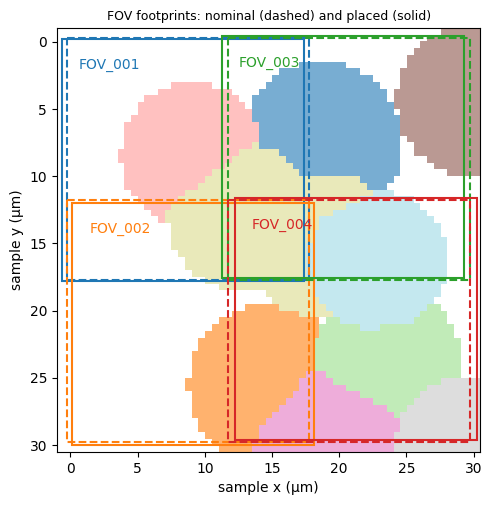

In [6]:
def footprint(origin_y, origin_x):
    # The rectangle covered by a FOV's voxels whose first voxel centre is at the origin.
    (_, ny, nx), (_, sy, sx) = FOV_SHAPE, SPACING
    return (origin_x - sx / 2, origin_y - sy / 2), nx * sx, ny * sy


labels_2d = scene.sample_labels["cell"].max(axis=0)
(gy, gx), (sy, sx) = scene.sample_grid.origin_zyx[1:], scene.sample_grid.spacing_zyx[1:]
extent = (gx - sx / 2, gx + (labels_2d.shape[1] - 0.5) * sx, gy + (labels_2d.shape[0] - 0.5) * sy, gy - sy / 2)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.imshow(np.ma.masked_equal(labels_2d, 0) % 20, cmap="tab20", extent=extent, interpolation="nearest", alpha=0.6)
for k, row in enumerate(truth.itertuples()):
    placed_yx = tuple(placed.loc[row.Index, ["origin_y", "origin_x"]])
    for (y, x), style in (((row.nominal_y, row.nominal_x), "--"), (placed_yx, "-")):
        corner, width, height = footprint(y, x)
        ax.add_patch(plt.Rectangle(corner, width, height, fill=False, ec=f"C{k}", ls=style, lw=1.5))
    ax.text(placed.loc[row.Index, "origin_x"] + 1, placed.loc[row.Index, "origin_y"] + 2, row.Index, color=f"C{k}")
ax.set_xlabel("sample x (µm)")
ax.set_ylabel("sample y (µm)")
ax.set_title("FOV footprints: nominal (dashed) and placed (solid)", fontsize=9)
plt.show()

## 5. `Dataset.export`

`Dataset.export` reads only saved files: the approved placement, each FOV's reference image
and assignment folder. On the route per FOV it assembles the sample's tables (one owner FOV
for each point of an overlap, so a molecule seen by two FOVs is counted once), writes
`sample.h5ad`, fuses the reference images into one projection and, with `fuse_labels`,
writes the sample's cell labels; both images are kept here at the acquired resolution
(`scale_yx=1.0`) ([Sample output](../../docs/sample-output-contract.md), [Assembly](../../docs/assembly-contract.md)).
`check_export` checks the folder against its record `export.json`.

In [7]:
EXPORT = OUTPUT / "export" / SAMPLE
export = dataset.export(SAMPLE, placement=PLACEMENT_DIR, output_dir=EXPORT,
                        config=ExportConfig(route="per_fov", fuse_labels=True,
                                            fusion=FusionConfig(images=("reference_merged",), scale_yx=1.0),
                                            labels=LabelConfig(scale_yx=1.0)))
check_export(EXPORT)
print("parts:", export.parts, " complete:", export.complete)
print("files:", sorted(p.relative_to(EXPORT).as_posix() for p in EXPORT.rglob("*") if p.is_file()))
assembly = load_assembly(EXPORT)
print({name: len(getattr(assembly, name)) for name in ("fovs", "cells", "molecules", "counts")})
for name in ("cells", "molecules"):
    print(name, assembly.record["counts"][name])

parts: {'assemble': 'written', 'fuse': 'written', 'segment': 'off', 'fuse_labels': 'written', 'export_spatialdata': 'off'}  complete: True
files: ['cell_labels.ome.tif', 'export.json', 'reference_merged_projection.ome.tif', 'sample.h5ad', 'tables/cells.csv', 'tables/counts.csv', 'tables/fovs.csv', 'tables/molecules.csv']
{'fovs': 4, 'cells': 18, 'molecules': 101, 'counts': 94}
cells {'input': 18, 'retained': 9, 'excluded': {'not_owner': 8, 'fov_not_placed': 0, 'duplicate_observation': 1}}
molecules {'input': 101, 'retained': 64, 'excluded': {'cell_not_owner': 31, 'not_owner': 1, 'outside_grid': 0, 'fov_not_placed': 0, 'cell_duplicate_observation': 5}}


The figure shows the fused reference image with the outlines of the exported cell labels
and the sample's retained molecules, coloured by whether they were assigned to a cell. The
watershed grew the cells over the amplicon signal, so their outlines follow the molecules
rather than the scene's true cell boundaries (the colours of the placement figure): the demo
shows the calls, not a tuned segmentation.

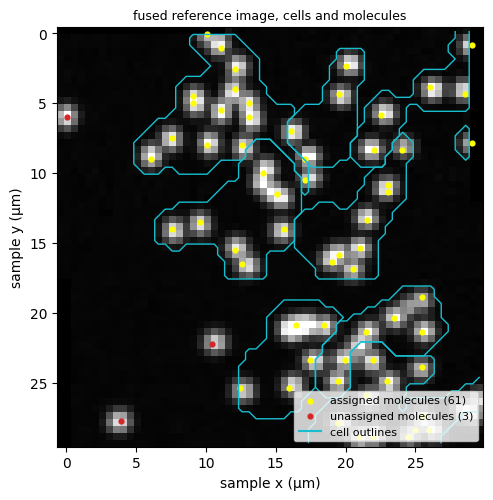

In [8]:
def image_extent(volume):
    # The (left, right, bottom, top) extent in sample µm of a loaded volume's Y-X plane.
    (sy, sx), (oy, ox), (ny, nx) = volume.metadata.spacing_zyx[1:], volume.metadata.origin_zyx[1:], volume.image.shape[1:3]
    return (ox - sx / 2, ox + (nx - 0.5) * sx, oy + (ny - 0.5) * sy, oy - sy / 2)


fused = load_volume(EXPORT / export.record["fusion"]["outputs"][0]["path"])
cell_labels = load_volume(EXPORT / export.record["labels"]["outputs"][0]["path"])
retained = assembly.molecules[assembly.molecules.assembly_status == "retained"]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
fused_plane = fused.image.max(axis=0).squeeze()
ax.imshow(fused_plane, cmap="gray", extent=image_extent(fused), vmax=np.percentile(fused_plane, 99.5))
label_plane = cell_labels.image.max(axis=0).squeeze()
left, right, bottom, top = image_extent(cell_labels)
ys = np.linspace(top, bottom, label_plane.shape[0] + 1)[:-1] + (bottom - top) / label_plane.shape[0] / 2
xs = np.linspace(left, right, label_plane.shape[1] + 1)[:-1] + (right - left) / label_plane.shape[1] / 2
for value in np.unique(label_plane[label_plane > 0]):
    ax.contour(xs, ys, (label_plane == value).astype(float), levels=[0.5], colors="tab:cyan", linewidths=1)
for status, colour in (("assigned", "yellow"), ("unassigned", "tab:red")):
    chosen = retained[retained.assignment_status == status]
    ax.scatter(chosen.sample_x, chosen.sample_y, s=12, c=colour, label=f"{status} molecules ({len(chosen)})")
ax.plot([], [], color="tab:cyan", label="cell outlines")
ax.legend(loc="lower right", fontsize=8)
ax.set_xlabel("sample x (µm)")
ax.set_ylabel("sample y (µm)")
ax.set_title("fused reference image, cells and molecules", fontsize=9)
plt.show()

## 6. `Dataset.report`

`Dataset.report` writes the sample's processing report, `report/<sample>/report.html` with
its record `report.json` and tables, from the saved run records, placement and export. It
describes the run and judges nothing ([Processing report](../../docs/report-contract.md)).
The cell prints the report's key numbers and draws the per-FOV counts from its FOV table;
a FOV's reads in counted cells exclude the cells that another FOV owns.

In [9]:
report = dataset.report(SAMPLE, FOV_IDS)
print("files:", sorted(p.relative_to(report.path).as_posix() for p in Path(report.path).rglob("*") if p.is_file()))
summary = report.record["summary"]
for key, value in summary.items():
    print(f"  {key}: {round(value, 3) if isinstance(value, float) else value}")
per_fov = pd.read_csv(Path(report.path) / "tables" / "fovs.csv").set_index("fov_id")
print("FOV table columns:", list(per_fov.columns))

files: ['report.html', 'report.json', 'tables/cells.csv', 'tables/fovs.csv', 'tables/intensity.csv', 'tables/mecr.csv', 'tables/population.csv', 'tables/problematic_fovs.csv', 'tables/readout_totals.csv', 'tables/reads_along_z.csv', 'tables/registration.csv', 'tables/steps.csv', 'tables/unavailable.csv']
  fovs_expected: 4
  fovs_with_run_record: 4
  fovs_succeeded: 4
  spots_median_per_fov: 29.5
  matched_fraction: 0.894
  counted_cells: 9
  reads_per_cell_median: 6.0
  genes_per_cell_median: 5.0
  cells_median_per_fov: 2.5
  reads_in_cells: 61
  h5ad_whole_count_sum: 61
  reads_in_cells_equal: True
FOV table columns: ['list_index', 'example', 'run_record', 'status', 'failed_step', 'failed_round', 'started_at', 'ended_at', 'run_seconds', 'placement_status', 'correction_z', 'correction_y', 'correction_x', 'footprint_y0', 'footprint_y1', 'footprint_x0', 'footprint_x1', 'centre_y', 'centre_x', 'spots', 'correct_form', 'matched', 'merged_by_deduplication', 'passed_filter', 'correct_form_f

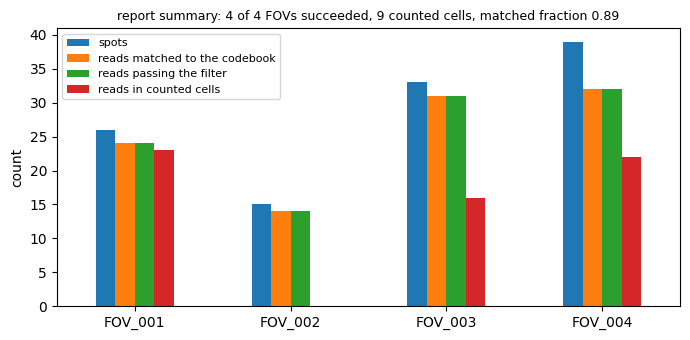

In [10]:
shown = {"spots": "spots", "matched": "reads matched to the codebook", "passed_filter": "reads passing the filter",
         "reads_in_cells": "reads in counted cells"}
ax = per_fov[list(shown)].rename(columns=shown).plot.bar(figsize=(7, 3.5), rot=0)
ax.set_ylabel("count")
ax.set_xlabel("")
ax.set_title(f"report summary: {summary['fovs_succeeded']} of {summary['fovs_expected']} FOVs succeeded, "
             f"{summary['counted_cells']} counted cells, matched fraction {summary['matched_fraction']:.2f}", fontsize=9)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Clean up

The notebook wrote only inside its temporary workspace; removing it leaves nothing behind.

In [11]:
written = sorted(p.relative_to(WORKSPACE).as_posix() for p in WORKSPACE.rglob("*") if p.is_file())
print(len(written), "files written, under", sorted({path.split("/")[0] for path in written}))
workspace.cleanup()
print("workspace removed:", not WORKSPACE.exists())

198 files written, under ['input', 'output', 'scene']
workspace removed: True
